In [16]:
import matplotlib.pyplot as plt
from matplotlib import gridspec
import numpy as np
import pandas as pd

In [19]:
datapath_in = f'/Users/carmennab/Dropbox/pb_new/SSF/1.1km/results/'

/var/folders/_1/fh2vf5m57871c546k_sf7xr80000gn/T/ipykernel_5435/3580740344.py:24: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  ax.errorbar(ticks, means,


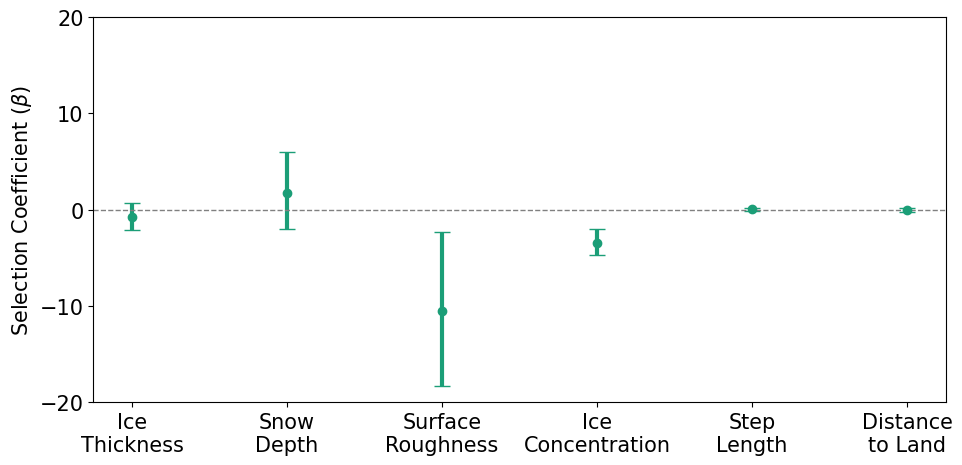

In [24]:
figpath = '/Users/carmennab/Dropbox/Apps/Overleaf/CRiceS_PolarBears_HB/figures/'

beta_vars = ["beta_SIT","beta_SD","beta_SR","beta_SIC","beta_steps","beta_distance"]
var_names = ['Ice\nThickness','Snow\nDepth','Surface\nRoughness','Ice\nConcentration','Step\nLength',
             'Distance\nto Land']

fig = plt.figure(figsize=(11,5))
spec = gridspec.GridSpec(ncols=1, nrows=1, hspace=0.2, wspace=0.4)
plt.rcParams.update({'font.size': 15})

ticks = np.arange(0,len(var_names))
ax = fig.add_subplot(spec[0])
summary = pd.read_csv(f'{datapath_in}4.csv')


means = [] ; lowers = [] ; uppers = []
for count, var_name in enumerate(var_names):

    sum_var = summary[summary['Unnamed: 0']==beta_vars[count]]
    means.append(sum_var["mean"].values[0])
    lowers.append(sum_var["hdi_3%"].values[0])
    uppers.append(sum_var["hdi_97%"].values[0])

ax.errorbar(ticks, means, 
             yerr=[np.array(means) - np.array(lowers), np.array(uppers) - np.array(means)],
             fmt='o-', capsize=6,markersize=6,lw=3, color='#1b9e77',ls='none')
ax.axhline(0, linestyle='--', color='gray',lw=1)
ax.set_ylabel(r'Selection Coefficient ($\beta$)')
ax.set_xticks(ticks)
ax.set_xticklabels(var_names)
ax.set_ylim([-20,20])
ax.set_yticks([-20,-10,0,10,20])

# plt.savefig(f'{figpath}SSF_results.jpg',bbox_inches = "tight", dpi = 400)